# FraudLens
### Financial Risk Intelligence & Fraud Analytics

An end-to-end data analytics and machine learning
platform for credit card fraud detection.

**Objectives:**
- Analyse financial transaction patterns.
- Perform exploratory and statistical data analysis.
- Investigate class imbalance and anomalies.
- Compare machine learning classification models.
- Evaluate fraud detection performance.
- Generate actionable financial risk insights.
- Integrate results into an interactive web dashboard.


In [ ]:
!pip install -q kagglehub xgboost imbalanced-learn

In [ ]:
import os
import json
import joblib
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

from xgboost import XGBClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

os.makedirs("visualizations", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

In [ ]:
path = kagglehub.dataset_download(
    "mlg-ulb/creditcardfraud"
)

df = pd.read_csv(
    os.path.join(path, "creditcard.csv")
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Dataset loaded successfully!
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
print("DATASET OVERVIEW")
print("-" * 50)

print("Total transactions:", len(df))
print("Total columns:", df.shape[1])
print("Missing values:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())

print("\nCLASS DISTRIBUTION")
print(df["Class"].value_counts())

print("\nFRAUD PERCENTAGE")
print(df["Class"].mean() * 100)

display(df.describe().T)

DATASET OVERVIEW
--------------------------------------------------
Total transactions: 284807
Total columns: 31
Missing values: 0
Duplicate records: 1081

CLASS DISTRIBUTION
Class
0    284315
1       492
Name: count, dtype: int64

FRAUD PERCENTAGE
0.1727485630620034


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


## 2. Data Cleaning and Preprocessing

This section investigates missing values, duplicate
records, data quality and class distribution to
prepare the dataset for statistical analysis and
machine learning.


In [ ]:
original_count = len(df)

df = df.drop_duplicates().reset_index(drop=True)

print("Original records:", original_count)
print("Cleaned records:", len(df))
print("Duplicates removed:", original_count - len(df))
print("Missing values:", df.isnull().sum().sum())

df.info()

Original records: 284807
Cleaned records: 283726
Duplicates removed: 1081
Missing values: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 283726 entries, 0 to 283725
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    283726 non-null  float64
 1   V1      283726 non-null  float64
 2   V2      283726 non-null  float64
 3   V3      283726 non-null  float64
 4   V4      283726 non-null  float64
 5   V5      283726 non-null  float64
 6   V6      283726 non-null  float64
 7   V7      283726 non-null  float64
 8   V8      283726 non-null  float64
 9   V9      283726 non-null  float64
 10  V10     283726 non-null  float64
 11  V11     283726 non-null  float64
 12  V12     283726 non-null  float64
 13  V13     283726 non-null  float64
 14  V14     283726 non-null  float64
 15  V15     283726 non-null  float64
 16  V16     283726 non-null  float64
 17  V17     283726 non-null  float64
 18  V18     283726 non-null  float64

## 3. Exploratory Data Analysis (EDA)

Exploratory data analysis is performed to identify
transaction patterns, class imbalance, anomalies,
feature relationships and potential fraud indicators.


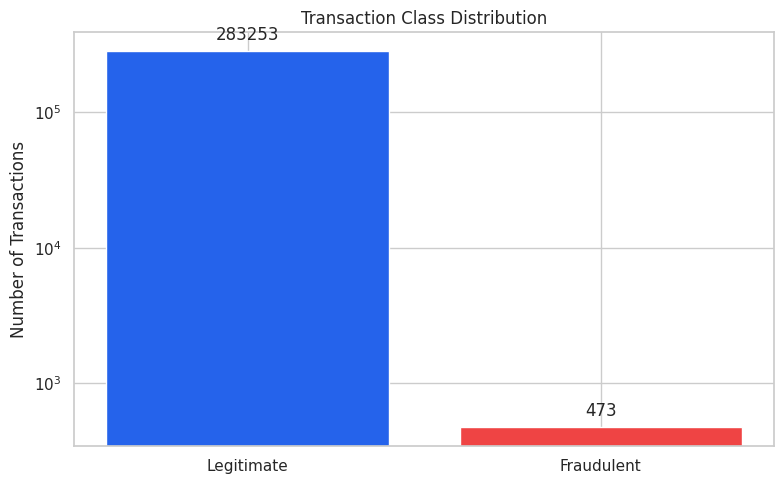

Fraud rate: 0.1667 %


In [ ]:
counts = df["Class"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Legitimate", "Fraudulent"],
    counts.values,
    color=["#2563EB", "#EF4444"]
)

ax.set_title("Transaction Class Distribution")
ax.set_ylabel("Number of Transactions")
ax.set_yscale("log")
ax.bar_label(bars, fmt="%d", padding=5)

plt.tight_layout()
plt.savefig("visualizations/class_distribution.png", dpi=200)
plt.show()

print("Fraud rate:", round(df["Class"].mean() * 100, 4), "%")

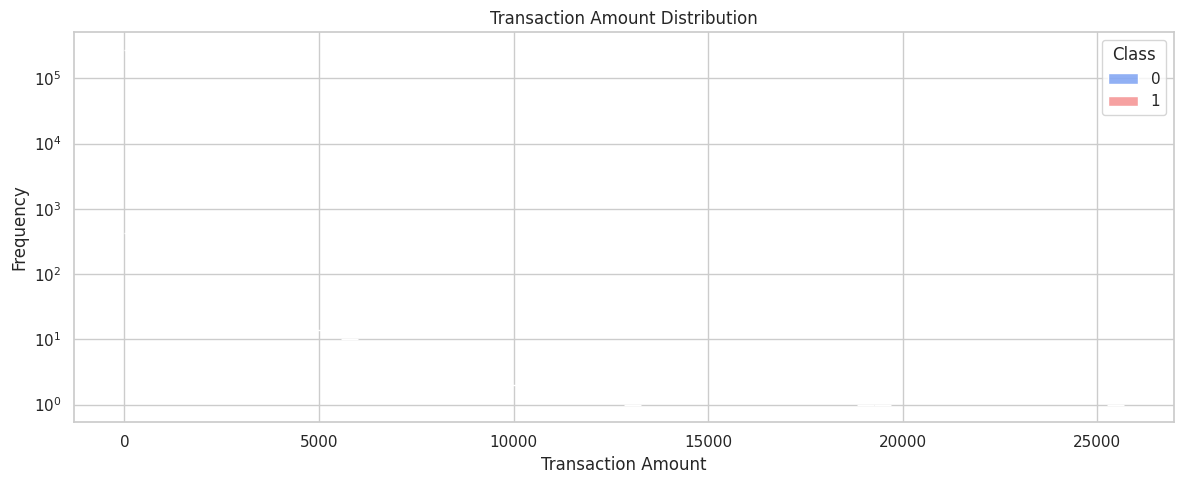

In [ ]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=60,
    log_scale=(False, True),
    palette=["#2563EB", "#EF4444"]
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("visualizations/amount_distribution.png", dpi=200)
plt.show()

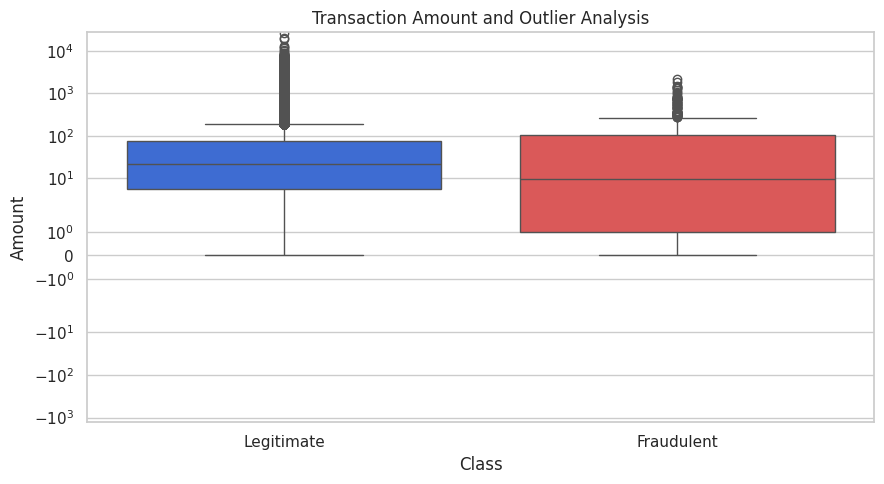

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount",
    hue="Class",
    palette=["#2563EB", "#EF4444"],
    legend=False
)

plt.yscale("symlog")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"])
plt.title("Transaction Amount and Outlier Analysis")

plt.tight_layout()
plt.savefig("visualizations/boxplot.png", dpi=200)
plt.show()

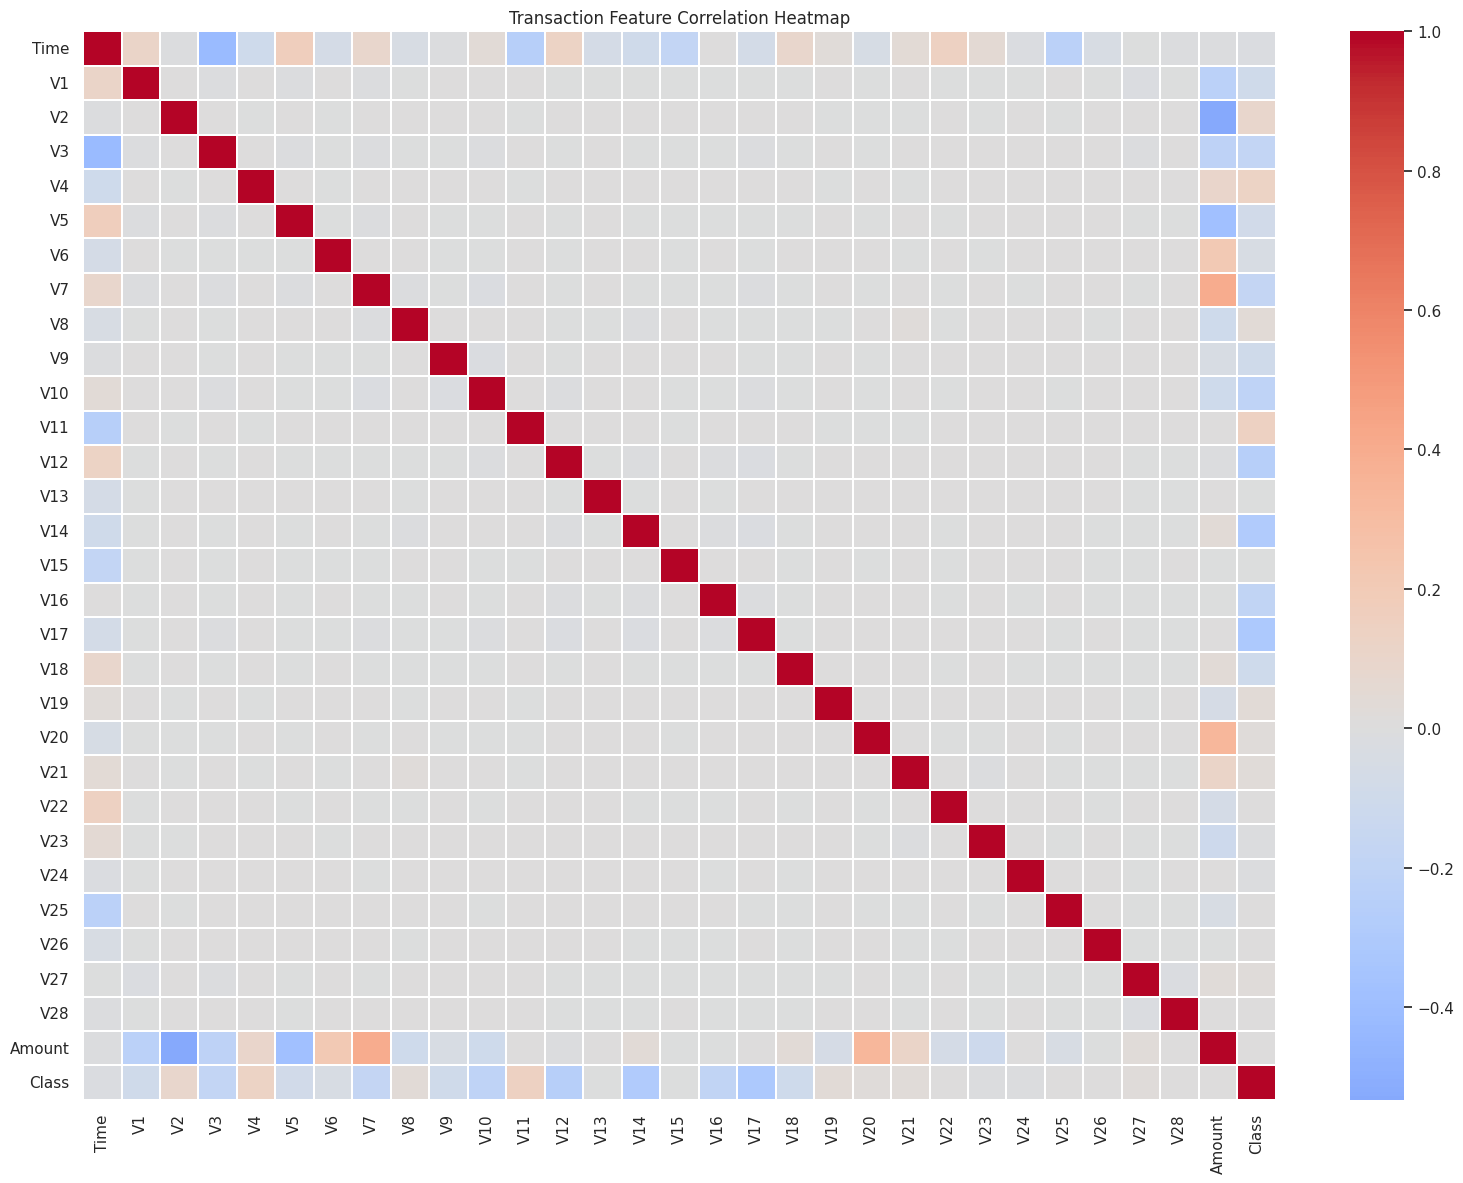

In [ ]:
plt.figure(figsize=(16, 12))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)

plt.title("Transaction Feature Correlation Heatmap")

plt.tight_layout()
plt.savefig("visualizations/correlation_heatmap.png", dpi=200)
plt.show()

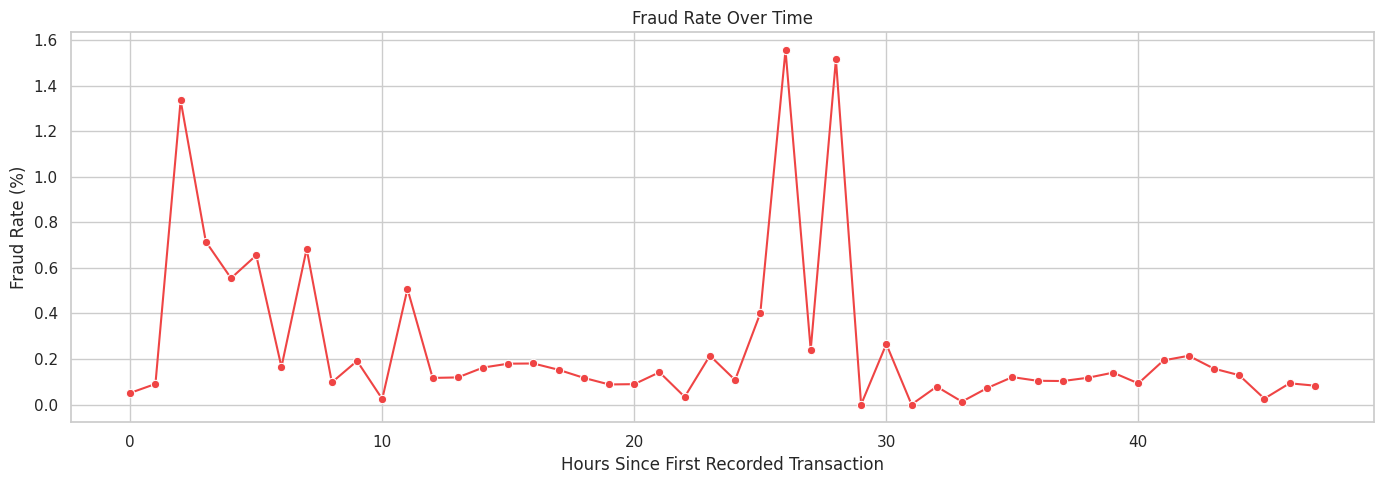

In [ ]:
df["Hour"] = (df["Time"] // 3600).astype(int)

hourly = df.groupby("Hour").agg(
    transactions=("Class", "count"),
    fraud_cases=("Class", "sum")
).reset_index()

hourly["fraud_rate"] = (
    hourly["fraud_cases"] / hourly["transactions"] * 100
)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=hourly,
    x="Hour",
    y="fraud_rate",
    marker="o",
    color="#EF4444"
)

plt.title("Fraud Rate Over Time")
plt.xlabel("Hours Since First Recorded Transaction")
plt.ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.savefig("visualizations/hourly_fraud.png", dpi=200)
plt.show()

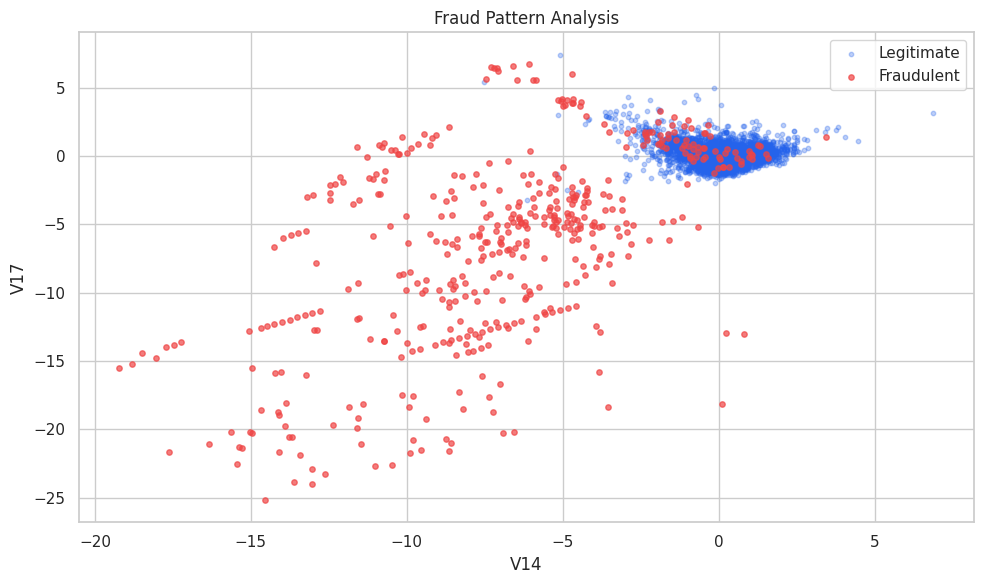

In [ ]:
plt.figure(figsize=(10, 6))

legitimate = df[df["Class"] == 0].sample(
    5000, random_state=42
)

fraud = df[df["Class"] == 1]

plt.scatter(
    legitimate["V14"],
    legitimate["V17"],
    alpha=0.3,
    s=10,
    label="Legitimate",
    color="#2563EB"
)

plt.scatter(
    fraud["V14"],
    fraud["V17"],
    alpha=0.7,
    s=15,
    label="Fraudulent",
    color="#EF4444"
)

plt.xlabel("V14")
plt.ylabel("V17")
plt.title("Fraud Pattern Analysis")
plt.legend()

plt.tight_layout()
plt.savefig("visualizations/scatter_plot.png", dpi=200)
plt.show()

In [ ]:
statistics = df.groupby("Class")["Amount"].agg(
    ["count", "sum", "mean", "median", "std", "min", "max"]
)

statistics.index = ["Legitimate", "Fraudulent"]

display(statistics)

print("\nFeatures most correlated with fraud:")

display(
    correlation["Class"]
    .drop("Class")
    .sort_values(key=abs, ascending=False)
    .head(10)
)

statistics.to_csv("results/transaction_statistics.csv")

,count,sum,mean,median,std,min,max
Legitimate,283253,25043410.29,88.413575,22.00,250.379023,0.0,25691.16
Fraudulent,473,58591.39,123.871860,9.82,260.211041,0.0,2125.87



Features most correlated with fraud:


,Class
V17,-0.313498
V14,-0.293375
V12,-0.250711
V10,-0.206971
V16,-0.187186
V3,-0.182322
V7,-0.172347
V11,0.149067
V4,0.129326
V18,-0.105340


## 4. Machine Learning and Predictive Analytics

Three supervised machine learning algorithms are
implemented and compared:

- Logistic Regression
- Random Forest
- XGBoost

The models are evaluated using classification metrics,
confusion matrices, ROC curves and precision-recall
analysis to identify the most effective fraud detection model.


In [ ]:
X = df.drop(columns=["Class", "Hour"])
y = df["Class"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

imbalance_ratio = (
    (y_train == 0).sum() / (y_train == 1).sum()
)

print("Class imbalance ratio:", imbalance_ratio)

Training samples: 198608
Validation samples: 42559
Testing samples: 42559
Class imbalance ratio: 599.02416918429


In [ ]:
import time

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=60,
        max_depth=15,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        scale_pos_weight=imbalance_ratio,
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=2
    )
}

training_times = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    start = time.time()
    model.fit(X_train, y_train)

    training_times[name] = round(time.time() - start, 2)

    filename = name.lower().replace(" ", "_")

    joblib.dump(
        model,
        f"models/{filename}.joblib"
    )

    print(f"Completed in {training_times[name]} seconds")

print("\nAll models trained successfully!")


Training Logistic Regression...
Completed in 3.96 seconds

Training Random Forest...
Completed in 83.41 seconds

Training XGBoost...
Completed in 4.83 seconds

All models trained successfully!


In [ ]:
results = []
predictions = {}
probabilities = {}

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred
    ).ravel()

    results.append({
        "Model": name,
        "TP": int(tp),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_prob),
        "Average Precision": average_precision_score(
            y_test, y_prob
        ),
        "Training Time": training_times[name]
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

results_df.to_csv(
    "results/model_comparison.csv",
    index=False
)

,Model,TP,TN,FP,FN,Accuracy,Precision,Recall,F1 Score,ROC AUC,Average Precision,Training Time
0,Logistic Regression,63,41401,1087,8,0.9743,0.0548,0.8873,0.1032,0.9608,0.6811,3.96
1,Random Forest,54,42482,6,17,0.9995,0.9000,0.7606,0.8244,0.9335,0.7843,83.41
2,XGBoost,57,42459,29,14,0.9990,0.6628,0.8028,0.7261,0.9581,0.7485,4.83


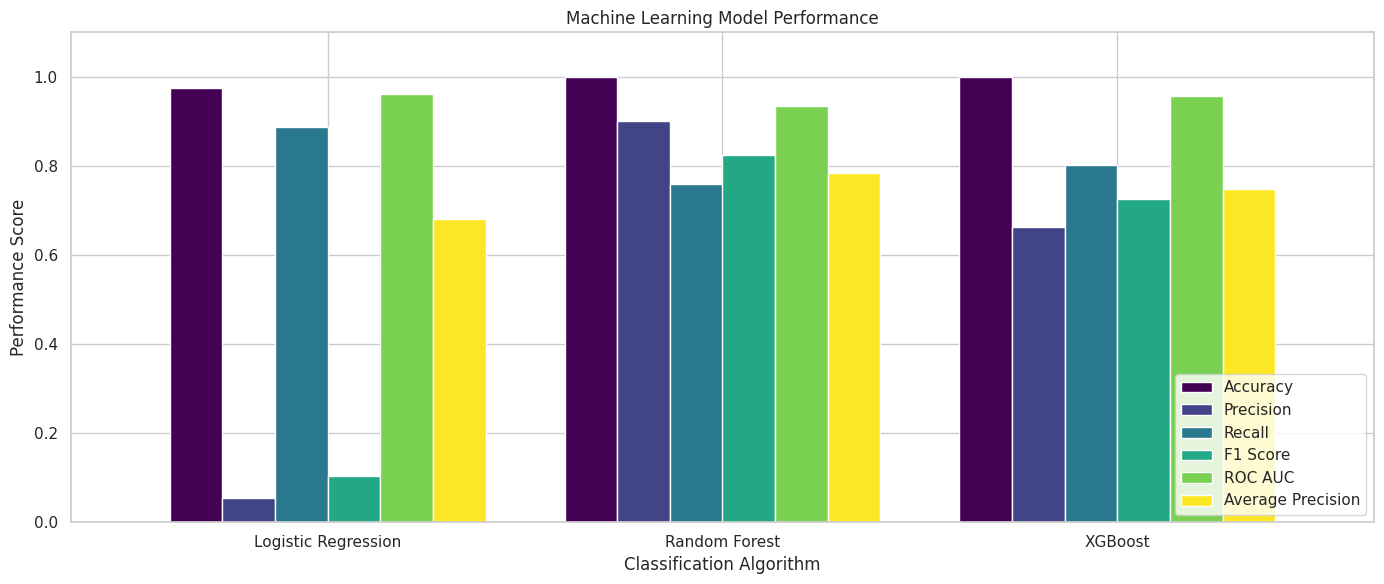

In [ ]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC",
    "Average Precision"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(14, 6),
    colormap="viridis",
    width=0.8
)

plt.title("Machine Learning Model Performance")
plt.ylabel("Performance Score")
plt.xlabel("Classification Algorithm")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    "visualizations/model_comparison.png",
    dpi=200
)

plt.show()

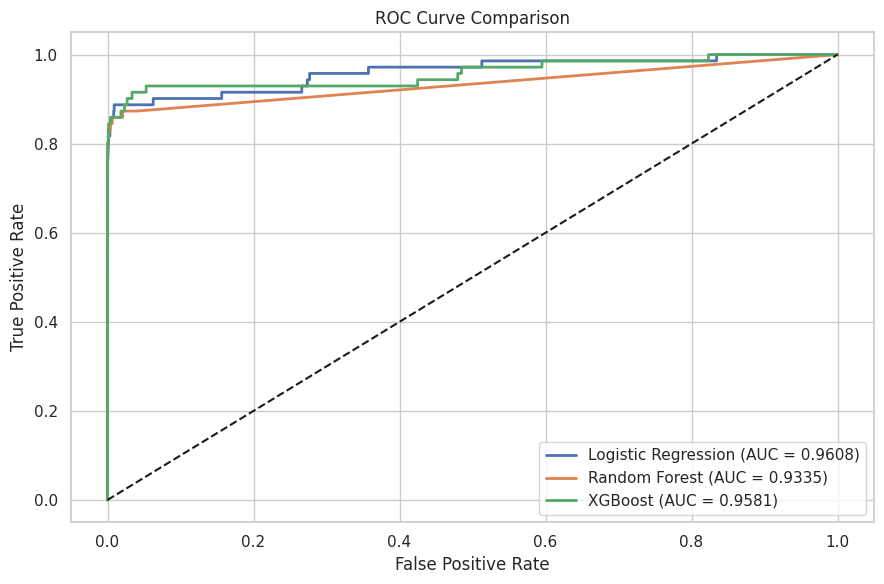

In [ ]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(9, 6))

for name, y_prob in probabilities.items():

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr, tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.4f})"
    )

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()

plt.savefig("visualizations/roc_curve.png", dpi=200)
plt.show()

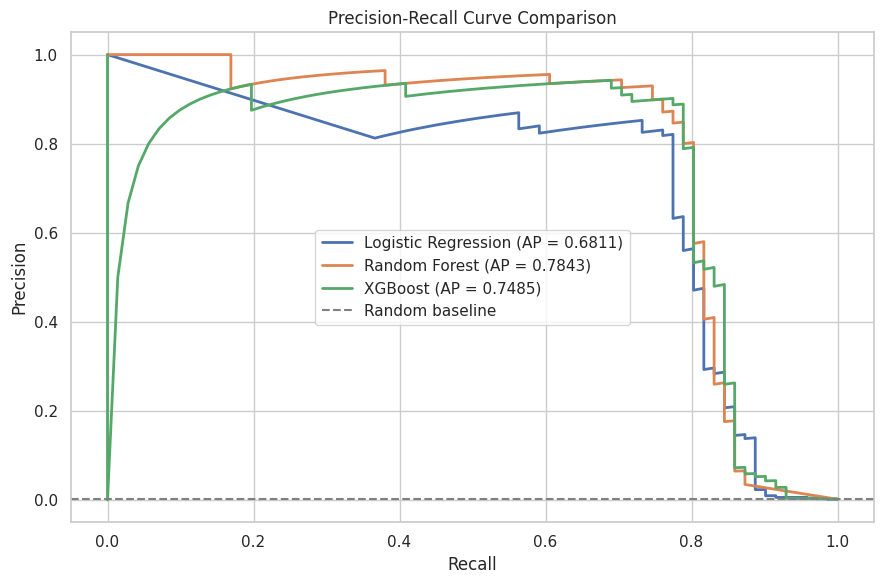

In [ ]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(9, 6))

for name, y_prob in probabilities.items():

    precision, recall, _ = precision_recall_curve(
        y_test, y_prob
    )

    ap = average_precision_score(y_test, y_prob)

    plt.plot(
        recall, precision,
        linewidth=2,
        label=f"{name} (AP = {ap:.4f})"
    )

plt.axhline(
    y_test.mean(),
    linestyle="--",
    color="gray",
    label="Random baseline"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.tight_layout()

plt.savefig(
    "visualizations/precision_recall.png",
    dpi=200
)

plt.show()

In [ ]:
validation_scores = {
    name: average_precision_score(
        y_val,
        model.predict_proba(X_val)[:, 1]
    )
    for name, model in models.items()
}

best_model_name = max(
    validation_scores,
    key=validation_scores.get
)

best_model = models[best_model_name]

val_prob = best_model.predict_proba(X_val)[:, 1]

threshold_results = []

for threshold in np.arange(0.01, 1.00, 0.01):

    pred = (val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, pred
    ).ravel()

    threshold_results.append({
        "threshold": round(float(threshold), 2),
        "precision": precision_score(
            y_val, pred, zero_division=0
        ),
        "recall": recall_score(y_val, pred),
        "f1": f1_score(y_val, pred),
        "tp": int(tp),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn)
    })

threshold_df = pd.DataFrame(threshold_results)

optimal = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

optimal_threshold = float(optimal["threshold"])

print("Best Model:", best_model_name)
print("Optimal Threshold:", optimal_threshold)

display(optimal)

threshold_df.to_csv(
    "results/threshold_analysis.csv",
    index=False
)

joblib.dump(best_model, "models/best_model.joblib")

Best Model: Random Forest
Optimal Threshold: 0.49


,48
threshold,0.490000
precision,0.962963
recall,0.732394
f1,0.832000
tp,52.000000
tn,42486.000000
fp,2.000000
fn,19.000000


['models/best_model.joblib']

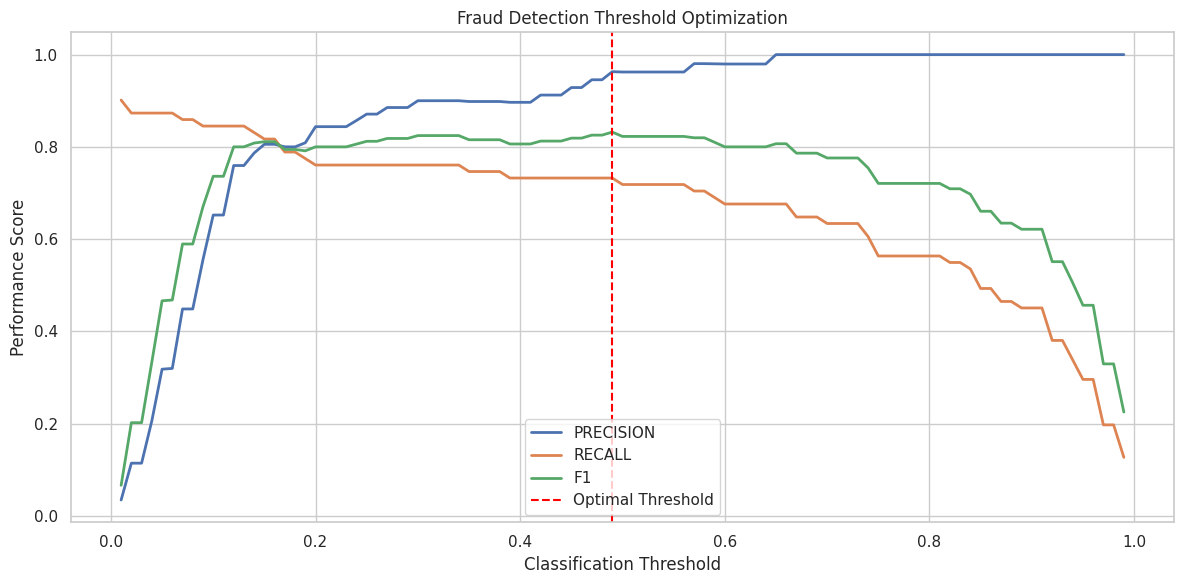

In [ ]:
plt.figure(figsize=(12, 6))

for metric in ["precision", "recall", "f1"]:
    plt.plot(
        threshold_df["threshold"],
        threshold_df[metric],
        label=metric.upper(),
        linewidth=2
    )

plt.axvline(
    optimal_threshold,
    color="red",
    linestyle="--",
    label="Optimal Threshold"
)

plt.title("Fraud Detection Threshold Optimization")
plt.xlabel("Classification Threshold")
plt.ylabel("Performance Score")
plt.legend()
plt.tight_layout()

plt.savefig(
    "visualizations/threshold_analysis.png",
    dpi=200
)

plt.show()

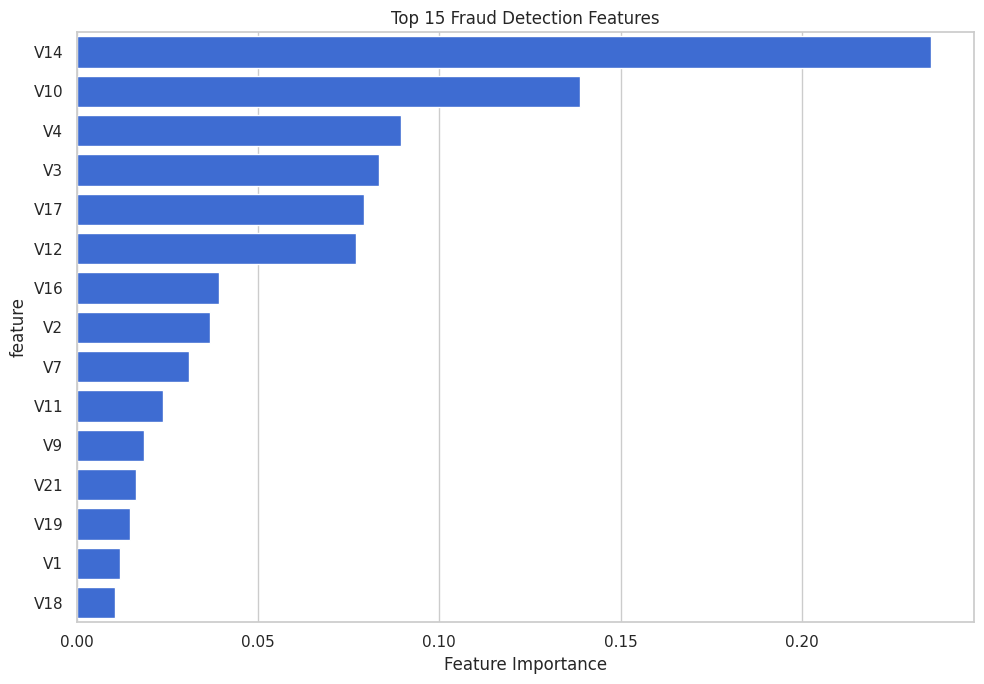

In [ ]:
importance = pd.DataFrame({
    "feature": X.columns,
    "importance": models[
        "Random Forest"
    ].feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance.head(15),
    x="importance",
    y="feature",
    color="#2563EB"
)

plt.title("Top 15 Fraud Detection Features")
plt.xlabel("Feature Importance")
plt.tight_layout()

plt.savefig(
    "visualizations/feature_importance.png",
    dpi=200
)

plt.show()

importance.to_csv(
    "results/feature_importance.csv",
    index=False
)

In [ ]:
financial_results = []

amounts = X_test["Amount"].to_numpy()
actual = y_test.to_numpy()

for name, prob in probabilities.items():

    pred = (prob >= 0.5).astype(int)

    detected = (actual == 1) & (pred == 1)
    missed = (actual == 1) & (pred == 0)
    false_alarm = (actual == 0) & (pred == 1)

    financial_results.append({
        "model": name,
        "detected_fraud_value": float(
            amounts[detected].sum()
        ),
        "missed_fraud_value": float(
            amounts[missed].sum()
        ),
        "false_alarm_value": float(
            amounts[false_alarm].sum()
        ),
        "total_fraud_value": float(
            amounts[actual == 1].sum()
        )
    })

financial_df = pd.DataFrame(financial_results)

display(financial_df.round(2))

financial_df.to_csv(
    "results/financial_impact.csv",
    index=False
)

,model,detected_fraud_value,missed_fraud_value,false_alarm_value,total_fraud_value
0,Logistic Regression,7196.96,2043.71,352845.63,9240.67
1,Random Forest,5749.63,3491.04,293.16,9240.67
2,XGBoost,6008.93,3231.74,3705.95,9240.67


In [ ]:
test_prob = best_model.predict_proba(X_test)[:, 1]

test_pred = (
    test_prob >= optimal_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, test_pred
).ravel()

final_metrics = {
    "model": best_model_name,
    "threshold": optimal_threshold,
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "recall": recall_score(y_test, test_pred),
    "f1": f1_score(y_test, test_pred),
    "roc_auc": roc_auc_score(y_test, test_prob),
    "average_precision": average_precision_score(
        y_test, test_prob
    ),
    "tp": int(tp),
    "tn": int(tn),
    "fp": int(fp),
    "fn": int(fn)
}

display(pd.DataFrame([final_metrics]).round(4))

,model,threshold,accuracy,precision,recall,f1,roc_auc,average_precision,tp,tn,fp,fn
0,Random Forest,0.49,0.9995,0.9,0.7606,0.8244,0.9335,0.7843,54,42482,6,17


In [ ]:
import sklearn
import xgboost

dashboard_data = {
    "overview": {
        "total_transactions": int(len(df)),
        "legitimate_transactions": int(
            (df["Class"] == 0).sum()
        ),
        "fraudulent_transactions": int(
            (df["Class"] == 1).sum()
        ),
        "fraud_rate": float(
            df["Class"].mean() * 100
        ),
        "total_transaction_value": float(
            df["Amount"].sum()
        ),
        "fraud_transaction_value": float(
            df.loc[df["Class"] == 1, "Amount"].sum()
        ),
        "average_transaction_amount": float(
            df["Amount"].mean()
        ),
        "duplicates_removed": int(
            original_count - len(df)
        )
    },

    "models": results_df.to_dict("records"),

    "best_model": final_metrics,

    "hourly_analysis": hourly.to_dict("records"),

    "feature_importance": importance.to_dict("records"),

    "threshold_analysis": threshold_df.to_dict("records"),

    "financial_impact": financial_df.to_dict("records"),

    "feature_names": X.columns.tolist(),

    "versions": {
        "scikit-learn": sklearn.__version__,
        "xgboost": xgboost.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "joblib": joblib.__version__
    }
}

with open("results/dashboard_data.json", "w") as f:
    json.dump(
        dashboard_data,
        f,
        indent=2,
        allow_nan=False
    )

print("Dashboard analytics exported successfully!")

Dashboard analytics exported successfully!


In [ ]:
test_samples = X_test.copy()
test_samples["actual_class"] = y_test

normal_samples = test_samples[
    test_samples["actual_class"] == 0
].sample(20, random_state=42)

fraud_samples = test_samples[
    test_samples["actual_class"] == 1
].sample(20, random_state=42)

samples = pd.concat([
    normal_samples,
    fraud_samples
]).reset_index(drop=True)

samples.to_csv(
    "results/sample_transactions.csv",
    index=False
)

print("40 sample transactions exported!")

40 sample transactions exported!


In [ ]:
import zipfile
from google.colab import files

with zipfile.ZipFile(
    "FraudLens_Artifacts.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for folder in [
        "models",
        "results",
        "visualizations"
    ]:

        for root, dirs, filenames in os.walk(folder):

            for filename in filenames:
                filepath = os.path.join(root, filename)
                archive.write(filepath)

files.download("FraudLens_Artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>